
<table>
    <tr>
        <td><img src='https://coastalrisk.live/wp-content/uploads/2018/05/cera_50x50.png' alt='Image' width='50' height=50'></td>
        <td><h1 align="left"><font color='green'>Visualizing Multiple NHC Tracks with Matplotlib </font></h1></td>
    </tr>
</table>


In [1]:
# Copyright (C): Carola Kaiser 2006-2026, Louisiana State University.
# This script is part of the Coastal Emergency Risks Assessment (CERA), a real-time visualization system for storm surge guidance.
# See https://cera.coastalrisk.live. This CERA script is Open Source software; distributed under the MIT License.

# Authors: Carola Kaiser, Efstratios Nikidis

# Part 1: Introduction

## 1.1 - Overview
This notebook loads every cataloged Atlantic ATCF best-track file, colors each track segment by maximum sustained wind, and exports one combined map.

**Pipeline**

```text
storm catalog -> ATCF files -> unique advisory points -> colored segments -> overview PNG
```

## 1.2 - Tutorial example ATCF catalog
The tutorial reads `tracks/storm_dat_files.csv`, which lists the 71 cataloged storms and maps each one to its `tracks/{year}_{storm}/bal*.dat` file. All paths are relative to this tutorial folder.

## 1.3 - Importing the Python libraries
The notebook uses pandas for tabular track data, Matplotlib for rendering, and Cartopy for the geographic map.

In [2]:
import csv
import re
from dataclasses import dataclass
from pathlib import Path
from typing import Iterable

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D

# Part 2: Track Visualization

## 2.1 - Paths and options
The input catalog and output image live directly in this tutorial folder, so the paths below are relative to it.

Change the output options here before running the remaining cells.

In [3]:
DATA_ROOT = Path("tracks")
OUTPUT_DIR = Path(".")

DPI = 300
FORMATS = ("png",)
SHOW_FIGURE = False
BRANDED = False
OUTPUT_STEM = "example_1_plot"

print("Data:  ", DATA_ROOT)
print("Output:", OUTPUT_DIR / f"{OUTPUT_STEM}.{FORMATS[0]}")

Data:   tracks
Output: example_1_plot.png


## 2.2 - Reading the storm catalog
Each CSV record keeps the year and storm name together with its cataloged `.dat` filename. This metadata is used for titles and date-range summaries.

In [4]:
@dataclass(frozen=True)
class CatalogEntry:
    year: str
    storm: str
    dat_path: Path


def load_catalog(data_root: Path) -> list[CatalogEntry]:
    """Read storm_dat_files.csv and resolve every ATCF file."""
    report_path = data_root / "storm_dat_files.csv"
    entries: list[CatalogEntry] = []

    with report_path.open(newline="", encoding="utf-8") as handle:
        for row in csv.DictReader(handle):
            if row["found"].strip().lower() != "yes":
                continue
            year = row["year"].strip()
            storm = row["storm_name"].strip()
            dat_file = row["dat_file"].strip()
            dat_path = data_root / f"{year}_{storm}" / dat_file
            if not dat_path.is_file():
                raise FileNotFoundError(f"Cataloged ATCF file is missing: {dat_path}")
            entries.append(CatalogEntry(year, storm, dat_path))

    if not entries:
        raise ValueError(f"No usable storm entries found in {report_path}")
    return entries

## 2.3 - Parsing ATCF track files
ATCF coordinates are stored in tenths of a degree, such as `286N` or `969W`. Repeated timestamps represent wind-radius records around the same center, so only one center point per timestamp is retained.

In [5]:
ATCF_DATETIME_FORMAT = "%Y%m%d%H"


def parse_coordinate(value: str) -> float:
    """Convert an ATCF coordinate from tenths of a degree to decimal degrees."""
    match = re.fullmatch(r"(\d+)([NSEW])", value.strip().upper())
    if not match:
        raise ValueError(f"Invalid ATCF coordinate: {value!r}")
    magnitude = int(match.group(1)) / 10.0
    return -magnitude if match.group(2) in {"S", "W"} else magnitude


def load_atcf_track(dat_path: Path) -> pd.DataFrame:
    """Load the fields needed to plot one ATCF best track."""
    parsed_rows = []
    with dat_path.open(newline="", encoding="utf-8") as handle:
        for line_number, fields in enumerate(csv.reader(handle), start=1):
            fields = [field.strip() for field in fields]
            if not fields or all(not field for field in fields):
                continue
            if len(fields) < 11:
                raise ValueError(
                    f"{dat_path}:{line_number} has {len(fields)} fields; expected at least 11"
                )
            try:
                parsed_rows.append(
                    {
                        "basin": fields[0],
                        "storm_number": fields[1],
                        "time": pd.to_datetime(
                            fields[2], format=ATCF_DATETIME_FORMAT, errors="raise"
                        ),
                        "technique": fields[4],
                        "latitude": parse_coordinate(fields[6]),
                        "longitude": parse_coordinate(fields[7]),
                        "vmax_kt": pd.to_numeric(fields[8], errors="coerce"),
                        "pressure_hpa": pd.to_numeric(fields[9], errors="coerce"),
                        "status": fields[10],
                    }
                )
            except ValueError as exc:
                raise ValueError(f"{dat_path}:{line_number}: {exc}") from exc

    track = pd.DataFrame(parsed_rows)
    if track.empty:
        raise ValueError(f"No track records found in {dat_path}")
    return (
        track.sort_values("time")
        .drop_duplicates(subset=["time"], keep="first")
        .reset_index(drop=True)
    )

## 2.4 - Preparing map geometry and the renderer
Adjacent advisory points become line segments. Each segment receives the mean wind speed of its two endpoints, converted from knots to metres per second.

A pale underlay keeps overlapping tracks visible. Stronger-wind segments are drawn last so the most intense portions remain readable. Branding is optional and is disabled in the options cell by default.

In [6]:
KNOTS_TO_METERS_PER_SECOND = 0.514444
WIND_SCALE_MIN_MPS = 0.0
WIND_SCALE_MAX_MPS = 85.0

WIND_COLORMAP = LinearSegmentedColormap.from_list(
    "cera_wind",
[
    (0.0000, "#D9F0F7"),  # Tropical depression: 0–38 mph
    (0.2484, "#1976B5"),  # Tropical storm: 39–73 mph
    (0.4713, "#F8E731"),  # Category 1: 74–95 mph
    (0.6115, "#EA832F"),  # Category 2: 96–110 mph
    (0.7070, "#D21835"),  # Category 3: 111–129 mph
    (0.8280, "#69162D"),  # Category 4: 130–156 mph
    (1.0000, "#000000")   # Category 5: 157+ mph
]

)


def full_data_extent(
    tracks: Iterable[tuple[CatalogEntry, pd.DataFrame]],
) -> list[float]:
    """Calculate a padded extent containing every advisory point."""
    frames = [track for _entry, track in tracks]
    lon_min = min(float(track["longitude"].min()) for track in frames)
    lon_max = max(float(track["longitude"].max()) for track in frames)
    lat_min = min(float(track["latitude"].min()) for track in frames)
    lat_max = max(float(track["latitude"].max()) for track in frames)
    lon_pad = max((lon_max - lon_min) * 0.03, 2.0)
    lat_pad = max((lat_max - lat_min) * 0.05, 2.0)
    return [
        max(-180.0, lon_min - lon_pad),
        min(180.0, lon_max + lon_pad),
        max(-90.0, lat_min - lat_pad),
        min(90.0, lat_max + lat_pad),
    ]


def collect_segments(
    tracks: Iterable[tuple[CatalogEntry, pd.DataFrame]],
) -> tuple[np.ndarray, np.ndarray]:
    """Build valid track segments and their mean endpoint winds in m/s."""
    segments: list[np.ndarray] = []
    wind_speeds: list[float] = []

    for _entry, track in tracks:
        points = track[["longitude", "latitude"]].to_numpy(dtype=float)
        winds = track["vmax_kt"].to_numpy(dtype=float) * KNOTS_TO_METERS_PER_SECOND
        for index in range(len(points) - 1):
            segment = points[index : index + 2]
            endpoint_winds = winds[index : index + 2]
            if not np.isfinite(segment).all() or not np.isfinite(endpoint_winds).any():
                continue
            segments.append(segment)
            wind_speeds.append(float(np.nanmean(endpoint_winds)))

    if not segments:
        raise ValueError("No valid track segments were found")
    segment_array = np.asarray(segments, dtype=float)
    wind_array = np.asarray(wind_speeds, dtype=float)
    order = np.argsort(wind_array, kind="stable")
    return segment_array[order], wind_array[order]

In [7]:
def add_base_features(ax) -> None:
    """Add consistent Natural Earth background features."""
    ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#D8DBDE", zorder=0)
    ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#FFFFFF", zorder=0)
    ax.add_feature(
        cfeature.LAKES.with_scale("10m"), facecolor="#D8DBDE",
        edgecolor="#A8A8A8", linewidth=0.25, zorder=1,
    )
    ax.add_feature(
        cfeature.RIVERS.with_scale("10m"), edgecolor="#A8A8A8",
        linewidth=0.22, alpha=0.75, zorder=1,
    )
    ax.add_feature(
        cfeature.COASTLINE.with_scale("10m"), edgecolor="#A8A8A8",
        linewidth=0.45, alpha=0.65, zorder=2,
    )
    ax.add_feature(
        cfeature.BORDERS.with_scale("10m"), edgecolor="#CFCFCF",
        linewidth=0.30, alpha=0.55, zorder=2,
    )
    ax.add_feature(
        cfeature.STATES.with_scale("10m"), edgecolor="#CFCFCF",
        linewidth=0.30, alpha=0.55, zorder=2,
    )


def export_overview(
    tracks: list[tuple[CatalogEntry, pd.DataFrame]],
    output_dir: Path,
    formats: Iterable[str],
    dpi: int,
    show: bool,
    branded: bool = False,
    output_stem: str = "all_storm_best_tracks",
) -> list[Path]:
    """Render and export the combined storm-track overview."""
    plt.rcParams.update(
        {
            "figure.dpi": 130,
            "savefig.dpi": 600,
            "font.family": "DejaVu Sans",
            "axes.titleweight": "bold",
            "axes.labelsize": 10,
            "axes.titlesize": 14,
        }
    )

    segments, winds_mps = collect_segments(tracks)
    norm = Normalize(vmin=WIND_SCALE_MIN_MPS, vmax=WIND_SCALE_MAX_MPS, clip=True)
    projection = ccrs.PlateCarree()

    fig = plt.figure(figsize=(14.0, 9.0), constrained_layout=False)
    map_height = 0.73 if branded else 0.82
    ax = fig.add_axes([0.055, 0.145, 0.89, map_height], projection=projection)
    extent = full_data_extent(tracks)
    extent[1] = min(extent[1], -25.0)
    ax.set_extent(extent, crs=projection)
    add_base_features(ax)
    ax.gridlines(
        draw_labels=False, linewidth=0.28, color="#9aa5ad",
        alpha=0.42, linestyle=(0, (2, 3)),
    )

    for spine in ax.spines.values():
        spine.set_linewidth(0.55)
        spine.set_edgecolor("#4b5563")

    ax.add_collection(
        LineCollection(
            segments, colors="#f8fafc", linewidths=3.0, alpha=0.78,
            transform=projection, zorder=4,
        )
    )
    colored_tracks = LineCollection(
        segments, cmap=WIND_COLORMAP, norm=norm, linewidths=2.0, alpha=0.92,
        transform=projection, zorder=5,
    )
    colored_tracks.set_array(winds_mps)
    ax.add_collection(colored_tracks)

    years = [int(entry.year) for entry, _track in tracks]
    advisory_count = sum(len(track) for _entry, track in tracks)
    if branded:
        fig.text(
            0.50, 0.952, f"CERA Hindcast Best Tracks ({min(years)}-{max(years)})",
            ha="center", va="center", fontsize=19, fontweight="bold", color="#111827",
        )
        fig.text(
            0.50, 0.915,
            f"{len(tracks)} Atlantic storm events | {advisory_count:,} advisory points | "
            "Track color shows local wind intensity",
            ha="center", va="center", fontsize=11.5, color="#4b5563",
        )
        fig.add_artist(
            Line2D(
                [0.055, 0.50], [0.892, 0.892], transform=fig.transFigure,
                color="#2b8cbe", linewidth=1.25, alpha=0.82,
            )
        )
        fig.add_artist(
            Line2D(
                [0.50, 0.945], [0.892, 0.892], transform=fig.transFigure,
                color="#2a9d62", linewidth=1.25, alpha=0.82,
            )
        )

    colorbar_ax = fig.add_axes([0.24, 0.082, 0.52, 0.026])
    colorbar = fig.colorbar(colored_tracks, cax=colorbar_ax, orientation="horizontal")
    colorbar.set_label(r"Maximum sustained wind (m s$^{-1}$)", fontsize=10.5, color="#374151")
    colorbar.set_ticks(np.arange(0, 81, 10))
    colorbar.ax.tick_params(labelsize=9, colors="#4b5563", width=0.5)
    colorbar.outline.set_linewidth(0.55)
    colorbar.outline.set_edgecolor("#6b7280")

    if branded:
        logo_path = Path("assets") / "cera_logo.png"
        if logo_path.is_file():
            logo_ax = fig.add_axes([0.055, 0.053, 0.036, 0.056])
            logo_ax.imshow(plt.imread(logo_path), interpolation="lanczos")
            logo_ax.set_axis_off()
        fig.text(
            0.096, 0.075, "Coastal Emergency Risks Assessment",
            ha="left", va="center", fontsize=7.6, fontweight="bold", color="#263238",
        )
        fig.text(
            0.945, 0.075, f"ATCF best-track archive | {min(years)}-{max(years)}",
            ha="right", va="center", fontsize=8.0, color="#6b7280",
        )

    output_dir.mkdir(parents=True, exist_ok=True)
    output_paths = []
    for file_format in formats:
        output_path = output_dir / f"{output_stem}.{file_format}"
        fig.savefig(output_path, dpi=dpi, facecolor="white")
        output_paths.append(output_path)

    if show:
        plt.show()
    else:
        plt.close(fig)
    return output_paths

## 2.5 - Loading and rendering the tracks
This cell validates the catalog and parses every storm before plotting. The summary makes it easy to spot an incomplete dataset.

The map is saved first and then displayed from the PNG. This keeps the inline result consistent with the exported figure.

In [8]:
catalog = load_catalog(DATA_ROOT)
tracks = [(entry, load_atcf_track(entry.dat_path)) for entry in catalog]

advisory_count = sum(len(track) for _entry, track in tracks)
wind_speeds_mps = (
    pd.concat([track["vmax_kt"] for _entry, track in tracks], ignore_index=True).dropna()
    * KNOTS_TO_METERS_PER_SECOND
)
year_values = [int(entry.year) for entry in catalog]

print(f"Tracks:           {len(tracks)}")
print(f"Years:            {min(year_values)}-{max(year_values)}")
print(f"Advisory points:  {advisory_count:,}")
print(f"Wind range:       {wind_speeds_mps.min():.1f}-{wind_speeds_mps.max():.1f} m/s")

Tracks:           71
Years:            2003-2025
Advisory points:  2,524
Wind range:       5.1-82.3 m/s


Saved: example_1_plot.png


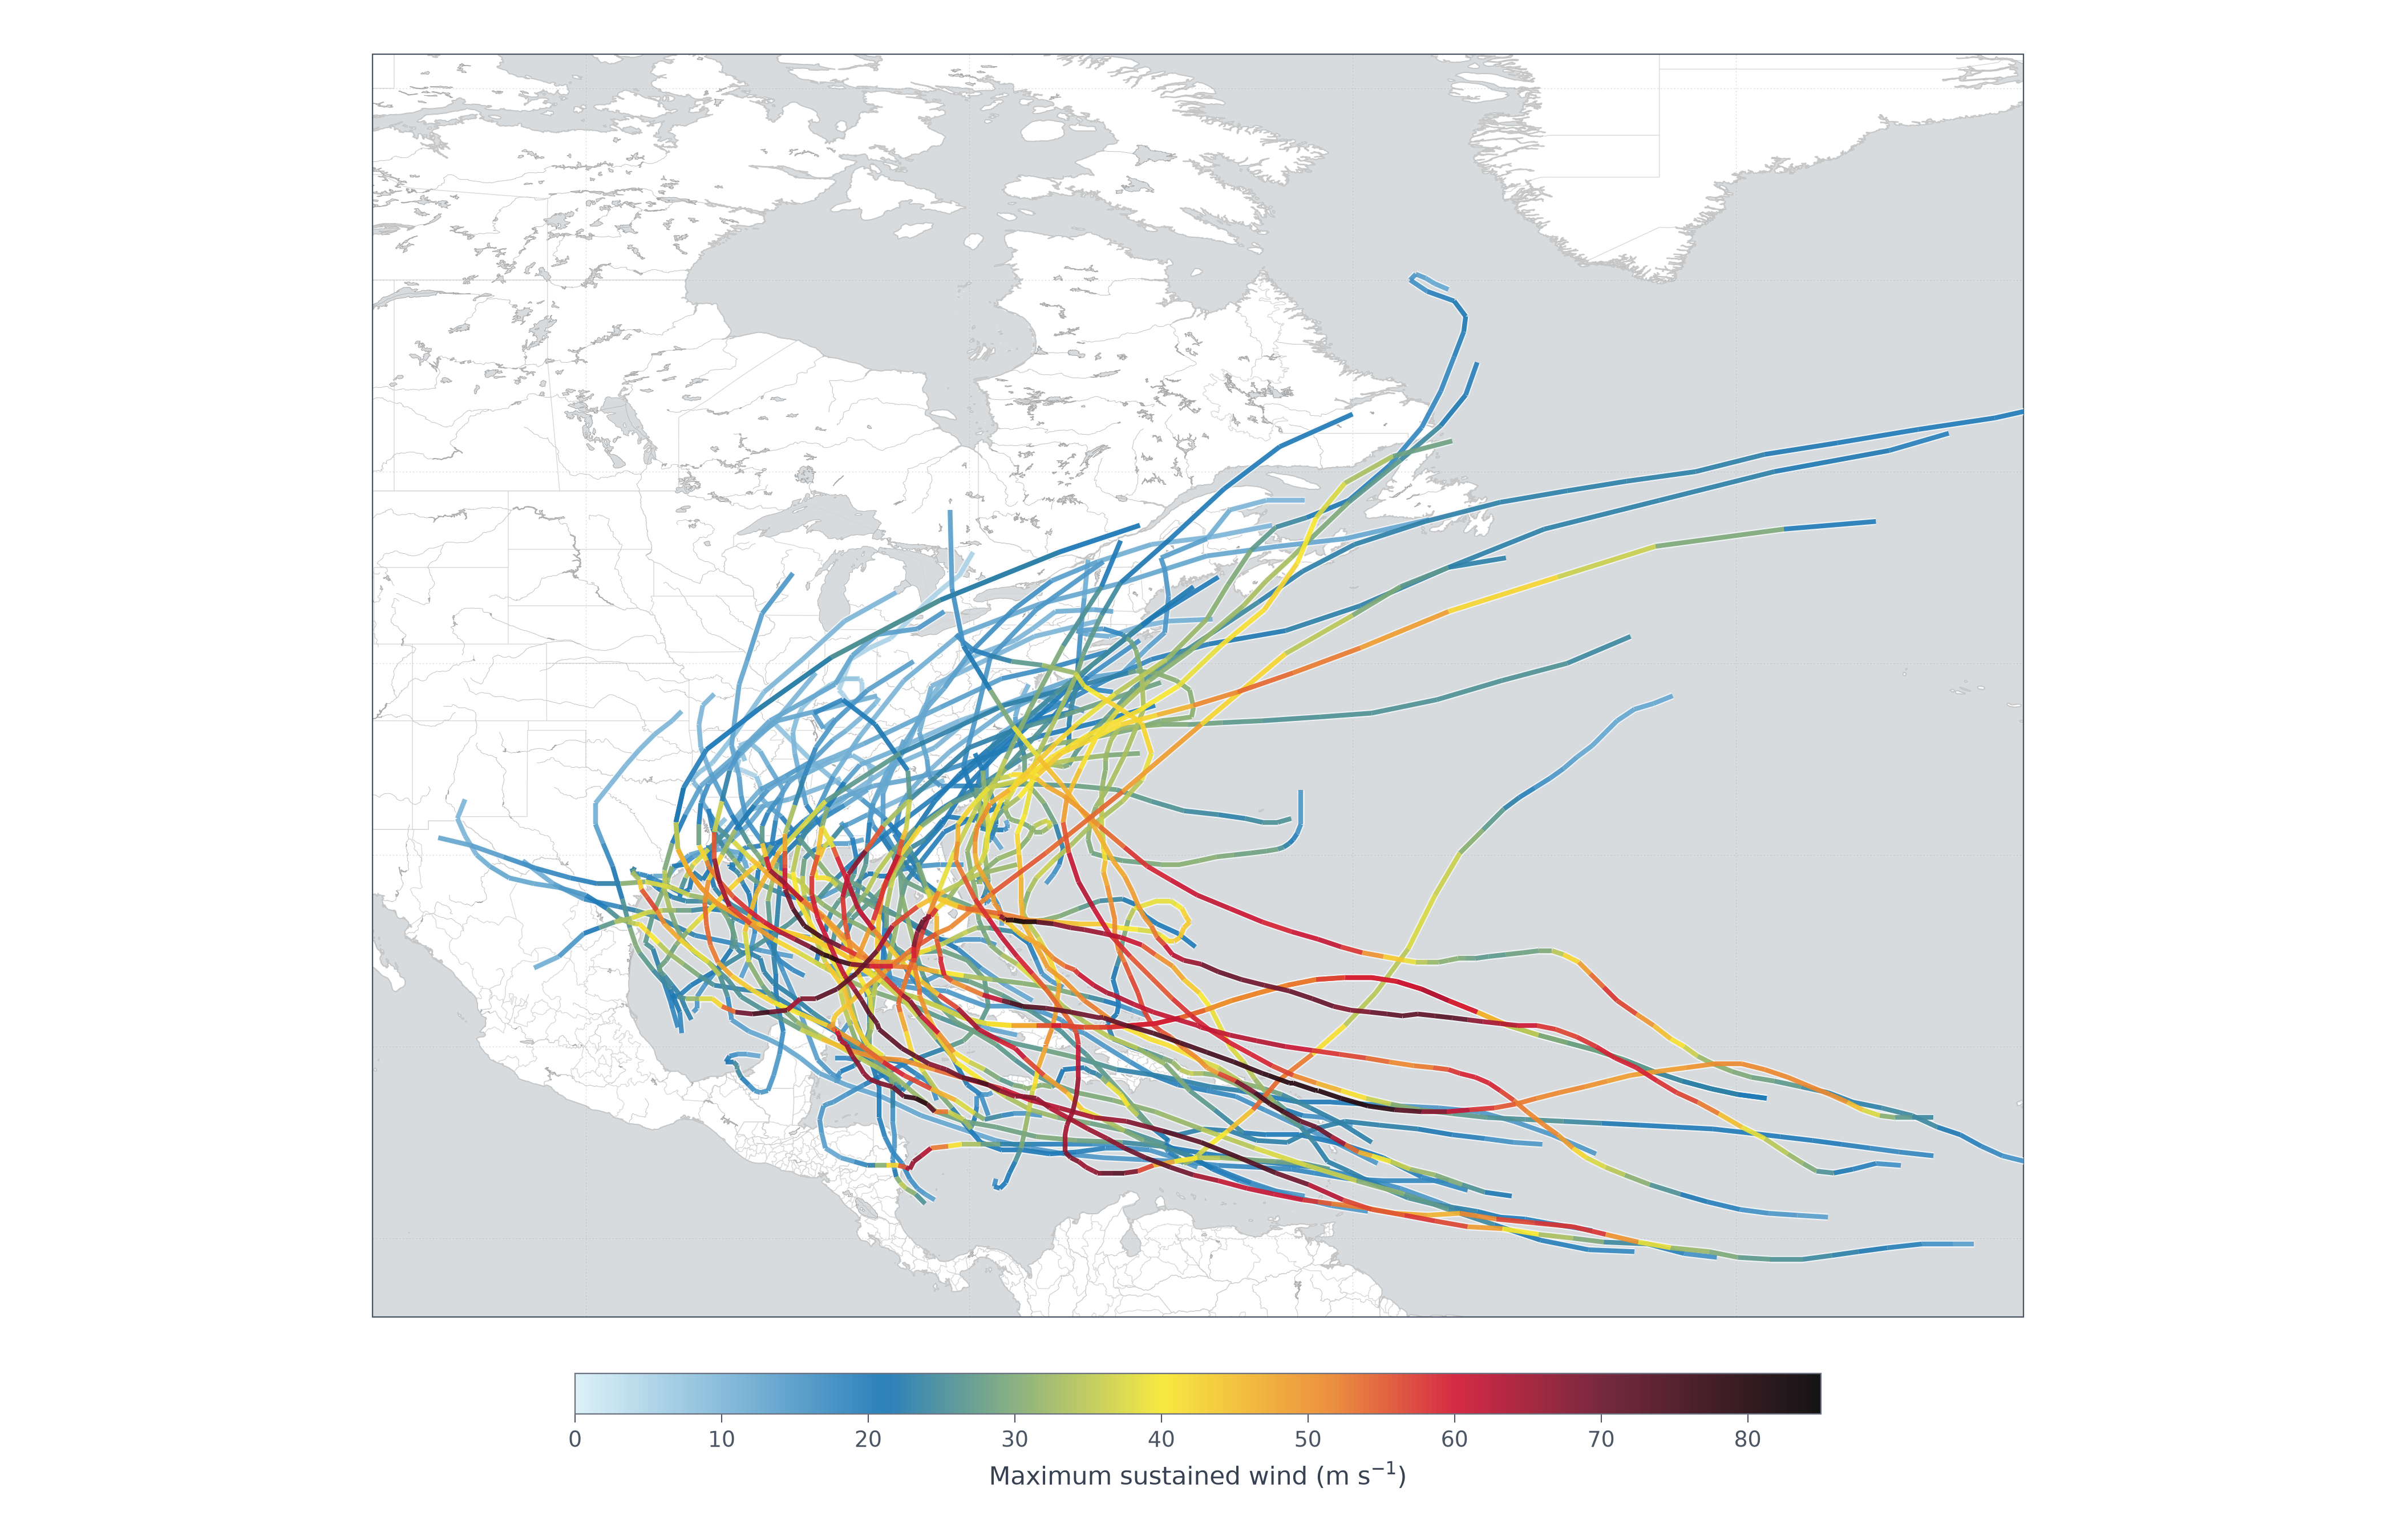

In [9]:
output_paths = export_overview(
    tracks,
    output_dir=OUTPUT_DIR,
    formats=FORMATS,
    dpi=DPI,
    show=SHOW_FIGURE,
    branded=BRANDED,
    output_stem=OUTPUT_STEM,
)

for output_path in output_paths:
    print("Saved:", output_path)

png_path = next((path for path in output_paths if path.suffix.lower() == ".png"), None)
if png_path is not None:
    display(Image(filename=str(png_path)))

# Part 3: Output

## 3.1 - Output file
The map is written to `example_1_plot.png` in this folder. To change the resolution, formats, branding, or output filename, edit only the options cell and re-run from there.